# TP : Classification d'images Chats vs Chiens — MLP vs CNN

**Contexte** : La classification d'images est une application importante du Deep Learning et de la vision par ordinateur.
L'objectif est de développer deux modèles capables de distinguer automatiquement :
- les images contenant des chats (*Cats*),
- les images contenant des chiens (*Dogs*).

Deux architectures sont étudiées : **MLP** (Multi-Layer Perceptron) et **CNN** (Convolutional Neural Network), puis comparées.

## 1. Importation des bibliothèques

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

print("TensorFlow :", tf.__version__)
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

TensorFlow : 2.21.0


## 2. Chargement du jeu de données

On utilise le jeu **Cats vs Dogs** (~23 000 images) via Hugging Face (`microsoft/cats_vs_dogs`), séparé en 80 % entraînement / 20 % validation.
Les images sont exportées une seule fois dans `data/PetImages/Cat` et `data/PetImages/Dog`.
Si vous avez déjà vos propres images, placez-les dans ces dossiers et la cellule ne retéléchargera rien.

In [2]:
# Le lien Microsoft ne renvoie plus un vrai zip -> on utilise Hugging Face (dataset "microsoft/cats_vs_dogs").
# Première fois seulement : décommentez la ligne suivante pour installer la bibliothèque
# %pip install datasets pillow

import pathlib
from datasets import load_dataset

DATA_ROOT = pathlib.Path("data")
PET_DIR = DATA_ROOT / "PetImages"
IMG_SIZE = (128, 128)
BATCH_SIZE = 64

# Export des images en dossiers Cat/ et Dog/ (une seule fois), redimensionnées en 128x128
if not (PET_DIR / "Dog").exists():
    print("Téléchargement du dataset (~800 Mo)...")
    hf = load_dataset("microsoft/cats_vs_dogs", split="train")
    names = hf.features["labels"].names          # ['cat', 'dog']
    for n in names:
        (PET_DIR / n.capitalize()).mkdir(parents=True, exist_ok=True)
    for i, ex in enumerate(hf):
        img = ex["image"].convert("RGB").resize(IMG_SIZE)
        img.save(PET_DIR / names[ex["labels"]].capitalize() / f"{i}.jpg", quality=95)
    print("Export terminé.")

print({d.name: len(list(d.glob("*.jpg"))) for d in PET_DIR.iterdir()})

train_ds = tf.keras.utils.image_dataset_from_directory(
    PET_DIR, validation_split=0.2, subset="training", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="binary")
val_ds = tf.keras.utils.image_dataset_from_directory(
    PET_DIR, validation_split=0.2, subset="validation", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="binary")

class_names = train_ds.class_names
print("Classes :", class_names)  # ['Cat', 'Dog']

c:\Users\lenovo\Desktop\deep-learning-and-transformers\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'Cat': 11741, 'Dog': 11669}
Found 23410 files belonging to 2 classes.
Using 18728 files for training.
Found 23410 files belonging to 2 classes.
Using 4682 files for validation.
Classes : ['Cat', 'Dog']


## 3. Exploration des données

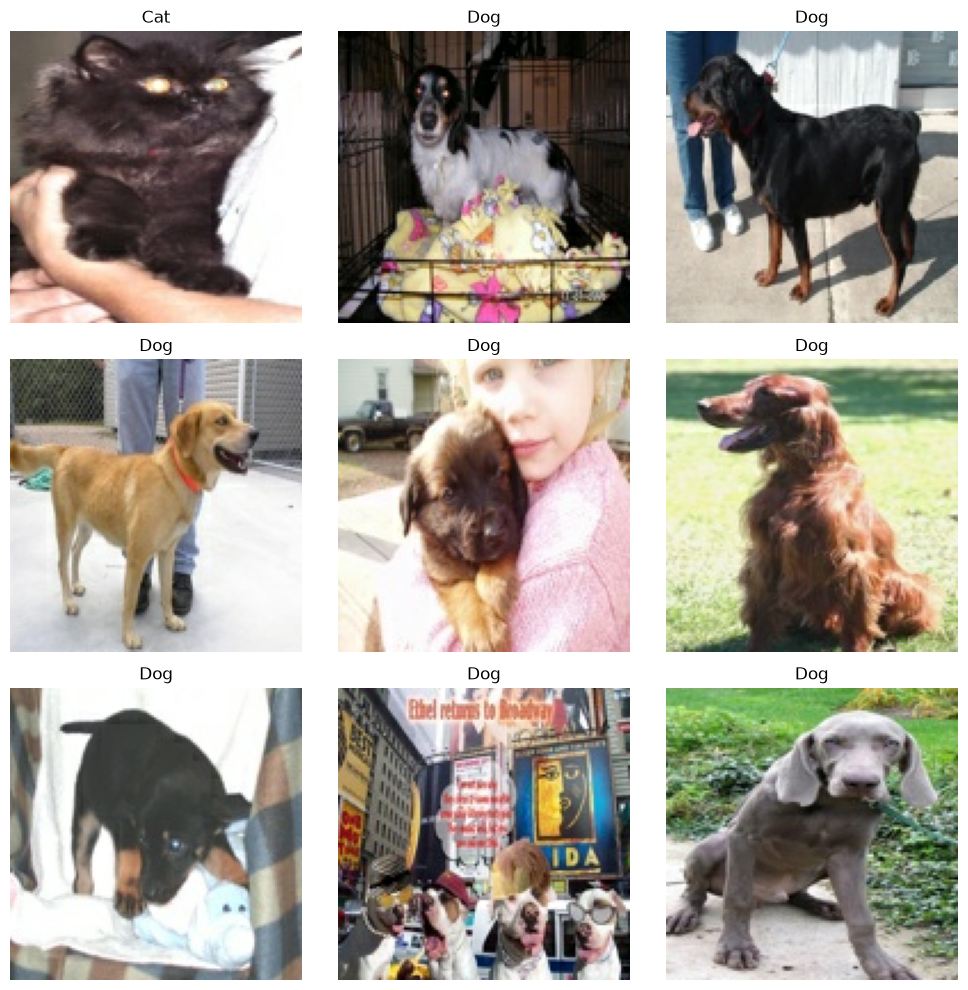

In [3]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i][0])])
        plt.axis("off")
plt.tight_layout()
plt.show()

## 4. Prétraitement et optimisation du pipeline

In [4]:
AUTOTUNE = tf.data.AUTOTUNE

normalization = layers.Rescaling(1./255)   # pixels de [0,255] vers [0,1]

train_ds_n = train_ds.map(lambda x, y: (normalization(x), y)).cache().prefetch(AUTOTUNE)
val_ds_n   = val_ds.map(lambda x, y: (normalization(x), y)).cache().prefetch(AUTOTUNE)

## 5. Modèle 1 : Multi-Layer Perceptron (MLP)

Le MLP **aplatit** l'image en un vecteur (128×128×3 = 49 152 valeurs) puis applique des couches entièrement connectées.
Il ne tient pas compte de la structure spatiale de l'image.

In [5]:
mlp = models.Sequential([
    layers.Input(shape=IMG_SIZE + (3,)),
    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid")
], name="MLP")

mlp.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
            loss="binary_crossentropy", metrics=["accuracy"])
mlp.summary()

Model: "MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 49152)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    25,166,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,314,177 (96.57 MB)

 Trainable params: 25,314,177 (96.57 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
EPOCHS = 5
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True)

history_mlp = mlp.fit(train_ds_n, validation_data=val_ds_n,
                      epochs=EPOCHS, callbacks=[early_stop])

Epoch 1/5


c:\Users\lenovo\Desktop\deep-learning-and-transformers\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


293/293 ━━━━━━━━━━━━━━━━━━━━ 83s 277ms/step - accuracy: 0.5160 - loss: 0.7629 - val_accuracy: 0.5703 - val_loss: 0.6812
Epoch 2/5
293/293 ━━━━━━━━━━━━━━━━━━━━ 75s 257ms/step - accuracy: 0.5471 - loss: 0.6873 - val_accuracy: 0.5935 - val_loss: 0.6825
Epoch 3/5
293/293 ━━━━━━━━━━━━━━━━━━━━ 72s 247ms/step - accuracy: 0.5509 - loss: 0.6852 - val_accuracy: 0.5150 - val_loss: 0.6886
Epoch 4/5
293/293 ━━━━━━━━━━━━━━━━━━━━ 71s 242ms/step - accuracy: 0.5598 - loss: 0.6813 - val_accuracy: 0.5991 - val_loss: 0.6773
Epoch 5/5
293/293 ━━━━━━━━━━━━━━━━━━━━ 71s 241ms/step - accuracy: 0.5769 - loss: 0.6760 - val_accuracy: 0.6087 - val_loss: 0.6687


## 6. Modèle 2 : Convolutional Neural Network (CNN)

Le CNN utilise des **couches de convolution** et de **pooling** qui extraient des caractéristiques locales (bords, textures, formes)
tout en partageant les poids, ce qui réduit fortement le nombre de paramètres.

In [7]:
cnn = models.Sequential([
    layers.Input(shape=IMG_SIZE + (3,)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(256, activation="relu"),
    layers.Dense(1, activation="sigmoid")
], name="CNN")

cnn.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
            loss="binary_crossentropy", metrics=["accuracy"])
cnn.summary()

Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,338,497 (8.92 MB)

 Trainable params: 2,338,497 (8.92 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True)

history_cnn = cnn.fit(train_ds_n, validation_data=val_ds_n,
                      epochs=EPOCHS, callbacks=[early_stop])

Epoch 1/5
293/293 ━━━━━━━━━━━━━━━━━━━━ 127s 429ms/step - accuracy: 0.6216 - loss: 0.6341 - val_accuracy: 0.7132 - val_loss: 0.5587
Epoch 2/5
293/293 ━━━━━━━━━━━━━━━━━━━━ 130s 443ms/step - accuracy: 0.7431 - loss: 0.5213 - val_accuracy: 0.7633 - val_loss: 0.4886
Epoch 3/5
293/293 ━━━━━━━━━━━━━━━━━━━━ 124s 422ms/step - accuracy: 0.7913 - loss: 0.4447 - val_accuracy: 0.7984 - val_loss: 0.4276
Epoch 4/5
293/293 ━━━━━━━━━━━━━━━━━━━━ 124s 423ms/step - accuracy: 0.8241 - loss: 0.3904 - val_accuracy: 0.8417 - val_loss: 0.3572
Epoch 5/5
293/293 ━━━━━━━━━━━━━━━━━━━━ 133s 455ms/step - accuracy: 0.8514 - loss: 0.3412 - val_accuracy: 0.8573 - val_loss: 0.3404


## 7. Courbes d'apprentissage

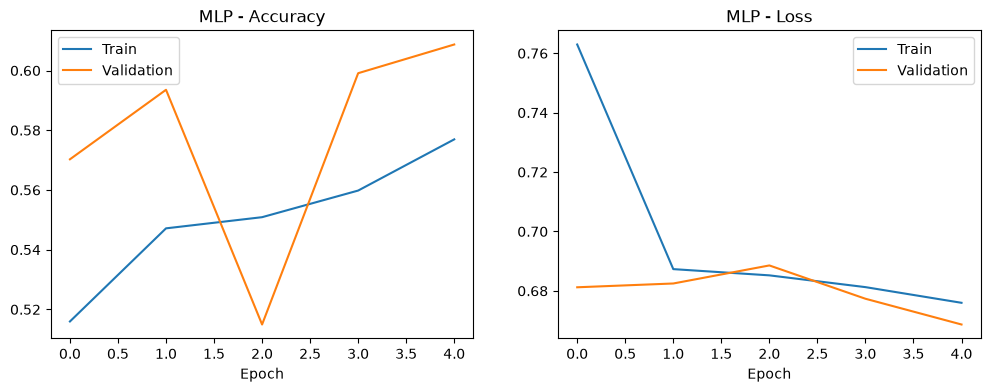

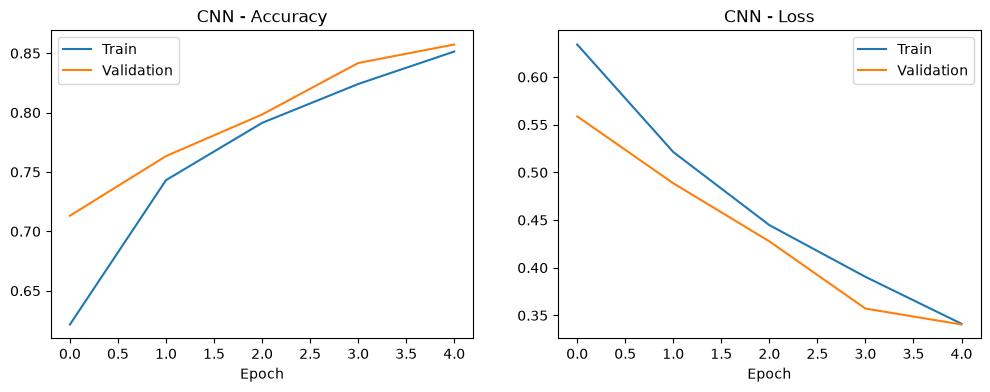

In [9]:
def plot_history(history, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(history.history["accuracy"], label="Train")
    ax[0].plot(history.history["val_accuracy"], label="Validation")
    ax[0].set_title(f"{title} - Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()
    ax[1].plot(history.history["loss"], label="Train")
    ax[1].plot(history.history["val_loss"], label="Validation")
    ax[1].set_title(f"{title} - Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
    plt.show()

plot_history(history_mlp, "MLP")
plot_history(history_cnn, "CNN")

## 8. Évaluation : matrice de confusion et rapport de classification

===== MLP =====
              precision    recall  f1-score   support

         Cat       0.64      0.46      0.54      2310
         Dog       0.59      0.75      0.66      2372

    accuracy                           0.61      4682
   macro avg       0.62      0.61      0.60      4682
weighted avg       0.62      0.61      0.60      4682



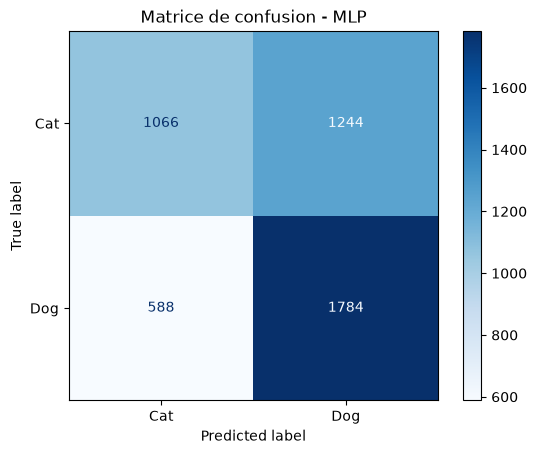

===== CNN =====
              precision    recall  f1-score   support

         Cat       0.85      0.86      0.86      2310
         Dog       0.86      0.86      0.86      2372

    accuracy                           0.86      4682
   macro avg       0.86      0.86      0.86      4682
weighted avg       0.86      0.86      0.86      4682



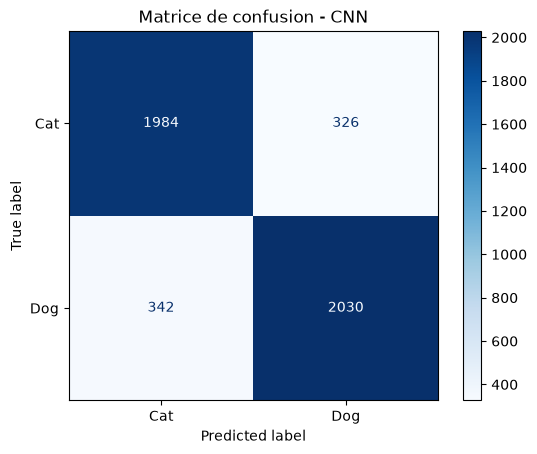

In [10]:
def evaluate(model, name):
    # une seule passe : on récupère prédictions ET étiquettes dans le même ordre
    y_true, y_prob = [], []
    for x, y in val_ds_n:
        y_prob.append(model.predict(x, verbose=0).ravel())
        y_true.append(y.numpy().ravel())
    y_true = np.concatenate(y_true).astype(int)
    y_prob = np.concatenate(y_prob)
    y_pred = (y_prob > 0.5).astype(int)
    print(f"===== {name} =====")
    print(classification_report(y_true, y_pred, target_names=class_names))
    cm = confusion_matrix(y_true, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues")
    plt.title(f"Matrice de confusion - {name}")
    plt.show()
    return model.evaluate(val_ds_n, verbose=0)

loss_mlp, acc_mlp = evaluate(mlp, "MLP")
loss_cnn, acc_cnn = evaluate(cnn, "CNN")

## 9. Étude comparative

,Modèle,Paramètres,Accuracy (val),Loss (val),Accuracy (train)
0,MLP,25314177,0.6087,0.6687,0.5769
1,CNN,2338497,0.8573,0.3404,0.8514


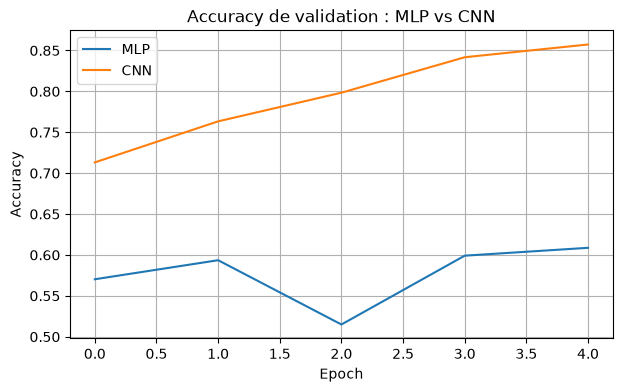

In [11]:
import pandas as pd

comparison = pd.DataFrame({
    "Modèle": ["MLP", "CNN"],
    "Paramètres": [mlp.count_params(), cnn.count_params()],
    "Accuracy (val)": [round(acc_mlp, 4), round(acc_cnn, 4)],
    "Loss (val)": [round(loss_mlp, 4), round(loss_cnn, 4)],
    "Accuracy (train)": [round(history_mlp.history["accuracy"][-1], 4),
                         round(history_cnn.history["accuracy"][-1], 4)],
})
display(comparison)

plt.figure(figsize=(7, 4))
plt.plot(history_mlp.history["val_accuracy"], label="MLP")
plt.plot(history_cnn.history["val_accuracy"], label="CNN")
plt.title("Accuracy de validation : MLP vs CNN")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.grid(True)
plt.show()

## 10. Prédictions sur des exemples

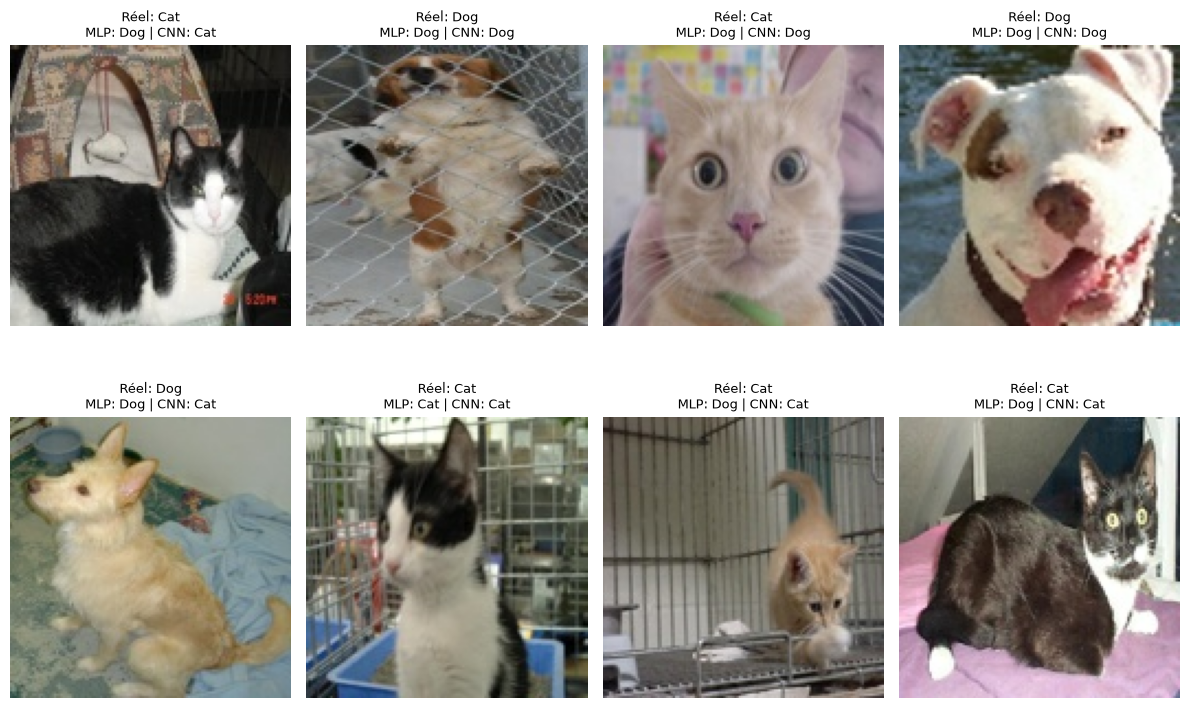

In [12]:
plt.figure(figsize=(12, 8))
for images, labels in val_ds.take(1):
    imgs_n = normalization(images)
    p_mlp = mlp.predict(imgs_n, verbose=0).ravel()
    p_cnn = cnn.predict(imgs_n, verbose=0).ravel()
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(f"Réel: {class_names[int(labels[i][0])]}\n"
                  f"MLP: {class_names[int(p_mlp[i] > .5)]} | CNN: {class_names[int(p_cnn[i] > .5)]}",
                  fontsize=9)
        plt.axis("off")
plt.tight_layout()
plt.show()

## 11. Conclusion

| Critère | MLP | CNN |
|---|---|---|
| Entrée | Image aplatie (perd la structure spatiale) | Image 2D conservée |
| Extraction de caractéristiques | Aucune (apprend directement sur les pixels) | Automatique (filtres de convolution) |
| Nombre de paramètres | Très élevé dans la 1ʳᵉ couche dense | Réduit grâce au partage des poids |
| Invariance à la translation | Non | Oui (convolution + pooling) |
| Risque de surapprentissage | Élevé | Plus faible |
| Performance attendue | ~55–65 % | ~75–85 % (sans augmentation de données) |

**Conclusion** : le CNN est nettement mieux adapté à la classification d'images : il exploite la structure spatiale, nécessite moins de paramètres
et généralise mieux que le MLP.

**Pistes d'amélioration** : data augmentation (`RandomFlip`, `RandomRotation`, `RandomZoom`), *Batch Normalization*, transfer learning (MobileNetV2, VGG16).